In [1]:
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from labellines import labelLines

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")

In [2]:
n = 10
eps = 1e-3

x = np.linspace(eps, 1 - eps, 1000)  # x = delta
y = np.linspace(0, 10, 1000)  # y = V/k
X, Y = np.meshgrid(x, y)

In [3]:
# Nash network
def nash_f1(x, n):
    return 1 / (x - x**2), r"$\frac{1}{\delta-\delta^2}$"


def nash_f2(x, n):
    return 1 / x, r"$\frac{1}{\delta}$"


def nash_f3(x, n):
    return 1 / (x + (n - 1) * x**2), r"$\frac{1}{\delta+(n-1)\delta^2}$"


# Efficient network
def eff_f1(x, n):
    return 1 / (2 * (x - x**2)), r"$\frac{1}{2(\delta-\delta^2)}$"


def eff_f2(x, n):
    return 1 / (2 * x + (n - 2) * x**2), r"$\frac{1}{2\delta+(n-2)\delta^2}$"

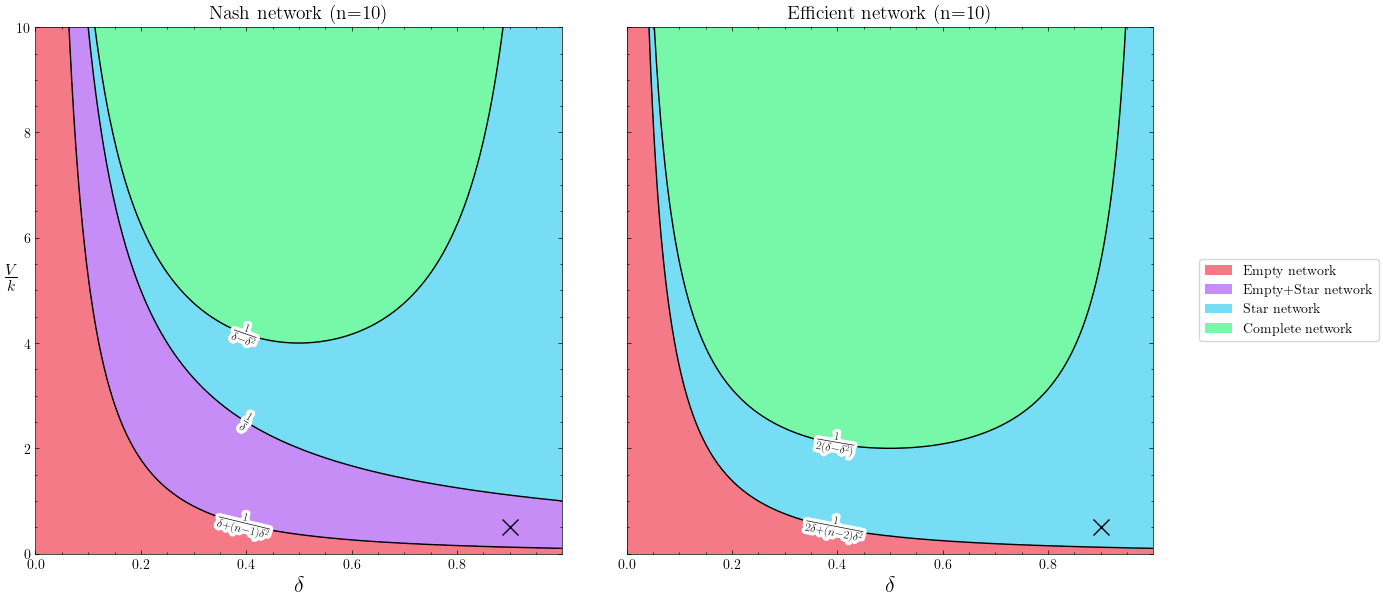

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True, constrained_layout=True)

# -------------------------
# Left panel: Nash network
# -------------------------

nash_y1, nash_label1 = nash_f1(x, n)
nash_y2, nash_label2 = nash_f2(x, n)
nash_y3, nash_label3 = nash_f3(x, n)

N1 = nash_y1[None, :]
N2 = nash_y2[None, :]
N3 = nash_y3[None, :]

# 0 = Empty, 1 = Empty+Star, 2 = Star, 3 = Complete
Z_nash = np.zeros_like(Y, dtype=int)
Z_nash[Y > N3] = 1
Z_nash[Y > N2] = 2
Z_nash[Y > N1] = 3

ax = axes[0]

nash_region_colors = ["#ee0d27", "#9a30f0", "#06c2ec", "#07f362"]
nash_region_labels = [
    "Empty network",
    "Empty+Star network",
    "Star network",
    "Complete network",
]

ax.contourf(
    X,
    Y,
    Z_nash,
    levels=[-0.5, 0.5, 1.5, 2.5, 3.5],
    colors=nash_region_colors,
    alpha=0.55,
)

(line1,) = ax.plot(x, nash_y1, color="black", label=nash_label1)
(line2,) = ax.plot(x, nash_y2, color="black", label=nash_label2)
(line3,) = ax.plot(x, nash_y3, color="black", label=nash_label3)

labelLines([line1, line2, line3], xvals=[0.4, 0.4, 0.4], fontsize=12)

ax.plot(0.9, 10 / (2 * n), "x", color="black", markersize=12)
ax.set_title(f"Nash network (n={n})", size=14)
ax.set_xlabel(r"$\delta$", size=16)
ax.set_ylabel(r"$\frac{V}{k}$", rotation=0, size=16)
ax.set_box_aspect(1)

# -------------------------
# Right panel: Efficient network
# -------------------------

eff_y1, eff_label1 = eff_f1(x, n)
eff_y2, eff_label2 = eff_f2(x, n)

E1 = eff_y1[None, :]
E2 = eff_y2[None, :]

# 0 = Empty, 1 = Star, 2 = Complete
Z_eff = np.zeros_like(Y, dtype=int)
Z_eff[Y > E2] = 1
Z_eff[Y > E1] = 2

ax = axes[1]

eff_region_colors = ["#ee0d27", "#06c2ec", "#07f362"]
eff_region_labels = ["Empty network", "Star network", "Complete network"]

ax.contourf(
    X, Y, Z_eff, levels=[-0.5, 0.5, 1.5, 2.5], colors=eff_region_colors, alpha=0.55
)

(line4,) = ax.plot(x, eff_y1, color="black", label=eff_label1)
(line5,) = ax.plot(x, eff_y2, color="black", label=eff_label2)

labelLines([line4, line5], xvals=[0.4, 0.4], fontsize=12)

ax.plot(0.9, 10 / (2 * n), "x", color="black", markersize=12)
ax.set_title(f"Efficient network (n={n})", size=14)
ax.set_xlabel(r"$\delta$", size=16)
ax.set_box_aspect(1)

# Common axis limits
for ax in axes:
    ax.set_xlim(0, x.max())
    ax.set_ylim(0, y.max())

# -------------------------
# Combined legend outside right
# -------------------------

region_handles = [
    Patch(facecolor="#ee0d27", edgecolor="none", alpha=0.55, label="Empty network"),
    Patch(facecolor="#9a30f0", edgecolor="none", alpha=0.55, label="Empty+Star network"),
    Patch(facecolor="#06c2ec", edgecolor="none", alpha=0.55, label="Star network"),
    Patch(facecolor="#07f362", edgecolor="none", alpha=0.55, label="Complete network"),
]

fig.legend(
    handles=region_handles,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=True,
)
plt.show()